<a href="https://colab.research.google.com/github/AthyaNivedita/AIML/blob/main/dt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

Saving studentdata.zip to studentdata.zip


In [ ]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("studentdata")

print(os.listdir("studentdata"))

['StudentsPerformance.csv']


In [ ]:
df = pd.read_csv("studentdata/StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
print("Shape of dataset:", df.shape)

Shape of dataset: (1000, 8)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
df.describe()
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [ ]:
X = df.drop('math score', axis=1)
y = df['math score']

print("Features:")
print(X.columns)

print("\nTarget:")
print("math score")

Features:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'reading score', 'writing score'],
      dtype='object')

Target:
math score


In [ ]:
categorical_features = [
    'gender',
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course'
]

numerical_features = [
    'reading score',
    'writing score'
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 7)
Testing data: (200, 7)


In [ ]:
dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(
            random_state=42,
            max_depth=5
        ))
    ]
)

dt_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'race/ethnicity',
                                                   'parental level of '
                                                   'education',
                                                   'lunch',
                                                   'test preparation course']),
                                                 ('num', 'passthrough',
                                                  ['reading score',
                                                   'writing score'])])),
                ('regressor',
                 DecisionTreeRegressor(max_depth=5, random_state=42))])

In [ ]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Regression")
print("-------------------------")
print("MAE  :", mae_dt)
print("MSE  :", mse_dt)
print("RMSE :", rmse_dt)
print("R²   :", r2_dt)

Decision Tree Regression
-------------------------
MAE  : 4.931523210662771
MSE  : 42.77161032657878
RMSE : 6.540000789493743
R²   : 0.8242299188020519


In [ ]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            max_depth=10
        ))
    ]
)

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'race/ethnicity',
                                                   'parental level of '
                                                   'education',
                                                   'lunch',
                                                   'test preparation course']),
                                                 ('num', 'passthrough',
                                                  ['reading score',
                                                   'writing score'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=10, random_state=42))])

In [ ]:
y_pred_rf = rf_model.predict(X_test)

In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("------------------------")
print("MAE  :", mae_rf)
print("MSE  :", mse_rf)
print("RMSE :", rmse_rf)
print("R²   :", r2_rf)

Random Forest Regression
------------------------
MAE  : 4.67348033773332
MSE  : 36.30153584055085
RMSE : 6.025075587953304
R²   : 0.850818712375232


In [ ]:
svr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', SVR(
            kernel='rbf',
            C=100,
            epsilon=0.1
        ))
    ]
)

svr_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'race/ethnicity',
                                                   'parental level of '
                                                   'education',
                                                   'lunch',
                                                   'test preparation course']),
                                                 ('num', 'passthrough',
                                                  ['reading score',
                                                   'writing score'])])),
                ('regressor', SVR(C=100))])

In [ ]:
y_pred_svr = svr_model.predict(X_test)

In [ ]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("Support Vector Regression")
print("-------------------------")
print("MAE  :", mae_svr)
print("MSE  :", mse_svr)
print("RMSE :", rmse_svr)
print("R²   :", r2_svr)

Support Vector Regression
-------------------------
MAE  : 5.309889384219516
MSE  : 44.69934995485412
RMSE : 6.6857572461804295
R²   : 0.8163078661039354


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Decision Tree Regression',
        'Random Forest Regression',
        'Support Vector Regression'
    ],
    'MAE': [
        mae_dt,
        mae_rf,
        mae_svr
    ],
    'MSE': [
        mse_dt,
        mse_rf,
        mse_svr
    ],
    'RMSE': [
        rmse_dt,
        rmse_rf,
        rmse_svr
    ],
    'R2 Score': [
        r2_dt,
        r2_rf,
        r2_svr
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Decision Tree Regression,4.931523,42.771610,6.540001,0.824230
1,Random Forest Regression,4.673480,36.301536,6.025076,0.850819
2,Support Vector Regression,5.309889,44.699350,6.685757,0.816308


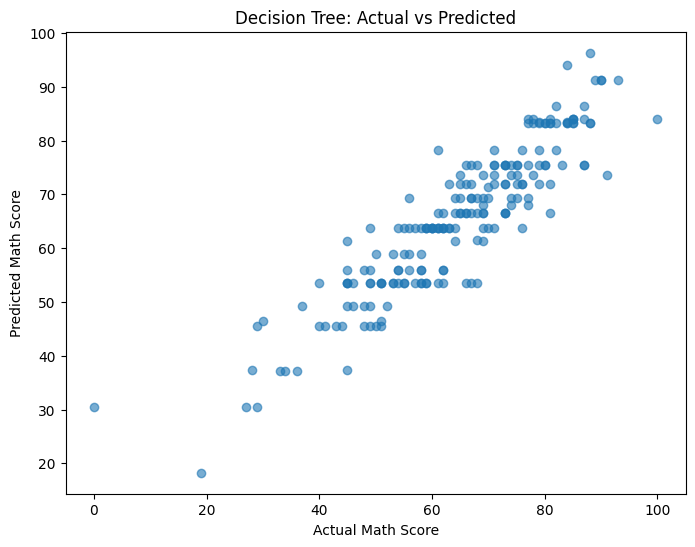

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_dt, alpha=0.6)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Decision Tree: Actual vs Predicted")

plt.show()

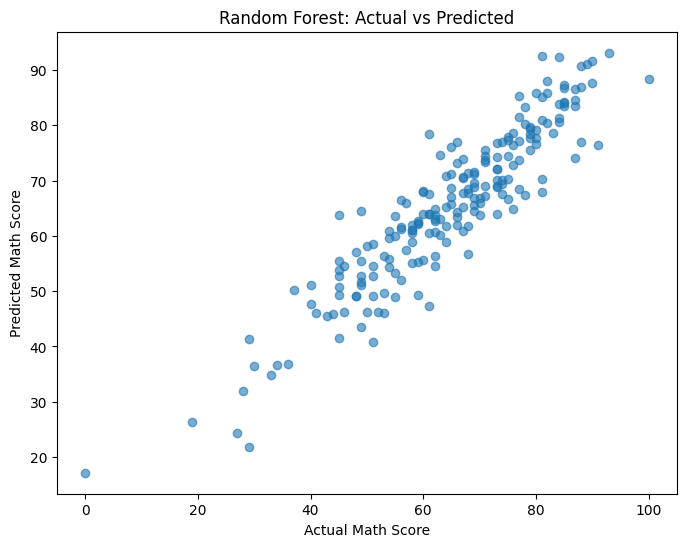

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_rf, alpha=0.6)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

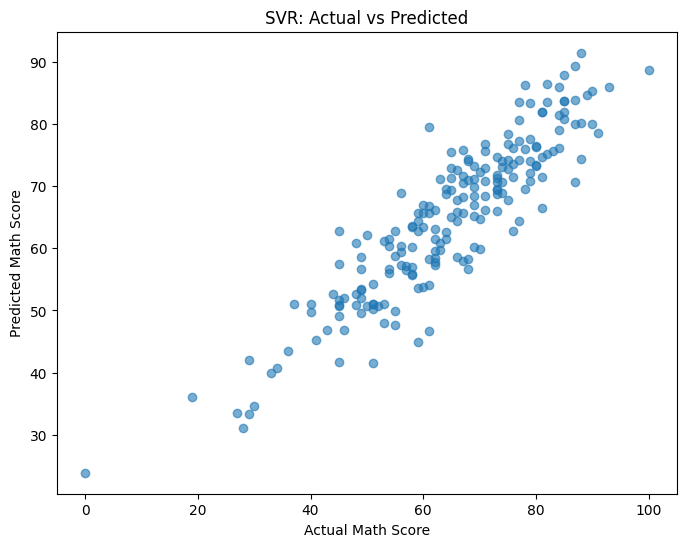

In [ ]:

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_svr, alpha=0.6)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("SVR: Actual vs Predicted")

plt.show()


In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'SVR': y_pred_svr
})

comparison.head(20)

,Actual,Decision Tree,Random Forest,SVR
0,91,73.622222,76.453675,78.477247
1,53,59.000000,56.299397,61.244009
2,80,75.451613,76.634414,73.361504
3,74,75.451613,76.953918,73.091468
4,84,83.333333,80.527125,81.450874
5,81,83.333333,85.041886,74.620162
6,69,68.071429,65.586521,65.159568
7,54,55.898305,54.424318,56.588361
8,87,75.451613,74.107814,70.646164
9,51,53.475000,52.720826,50.180065


In [ ]:
df['result'] = df['math score'].apply(
    lambda x: 'Pass' if x >= 40 else 'Fail'
)

    math score result
0           72   Pass
1           69   Pass
2           90   Pass
3           47   Pass
4           76   Pass
5           71   Pass
6           88   Pass
7           40   Pass
8           64   Pass
9           38   Fail
10          58   Pass
11          40   Pass
12          65   Pass
13          78   Pass
14          50   Pass
15          69   Pass
16          88   Pass
17          18   Fail
18          46   Pass
19          54   Pass
result
Pass    960
Fail     40
Name: count, dtype: int64


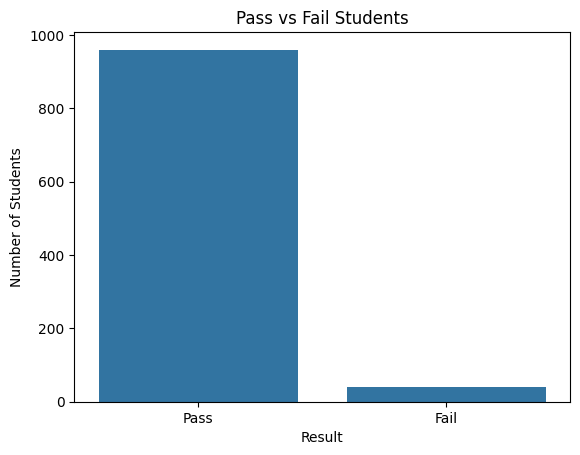

In [ ]:
print(df[['math score', 'result']].head(20))
print(df['result'].value_counts())
sns.countplot(data=df, x='result')

plt.title("Pass vs Fail Students")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.show()

In [ ]:
X = df.drop(['math score', 'result'], axis=1)
y = df['result']

In [ ]:
categorical_features = [
    'gender',
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course'
]

numerical_features = [
    'reading score',
    'writing score'
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numerical_features)
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 7)
Testing data: (200, 7)


In [ ]:
dt_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

dt_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'race/ethnicity',
                                                   'parental level of '
                                                   'education',
                                                   'lunch',
                                                   'test preparation course']),
                                                 ('num', 'passthrough',
                                                  ['reading score',
                                                   'writing score'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
y_pred_dt = dt_model.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)
print("Decision Tree Classification Report")
print("-----------------------------------")

print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.965
Decision Tree Classification Report
-----------------------------------
              precision    recall  f1-score   support

        Fail       0.57      0.50      0.53         8
        Pass       0.98      0.98      0.98       192

    accuracy                           0.96       200
   macro avg       0.78      0.74      0.76       200
weighted avg       0.96      0.96      0.96       200



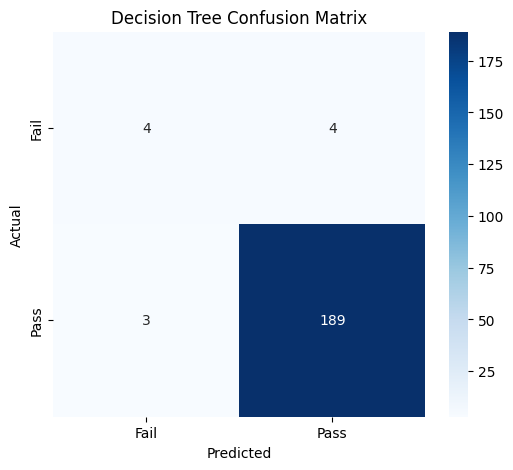

In [ ]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [ ]:
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            max_depth=10
        ))
    ]
)

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'race/ethnicity',
                                                   'parental level of '
                                                   'education',
                                                   'lunch',
                                                   'test preparation course']),
                                                 ('num', 'passthrough',
                                                  ['reading score',
                                                   'writing score'])])),
                ('classifier',
                 RandomForestClassifier(max_depth=10, random_state=42))])

In [ ]:
y_pred_rf = rf_model.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)
print("Random Forest Classification Report")
print("------------------------------------")

print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.97
Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

        Fail       1.00      0.25      0.40         8
        Pass       0.97      1.00      0.98       192

    accuracy                           0.97       200
   macro avg       0.98      0.62      0.69       200
weighted avg       0.97      0.97      0.96       200



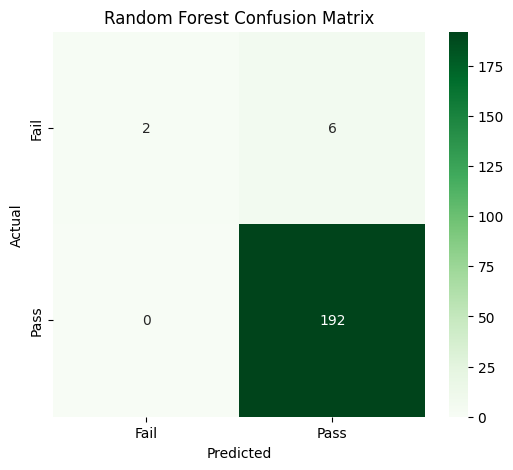

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Decision Tree Classifier',
        'Random Forest Classifier'
    ],
    'Accuracy': [
        accuracy_dt,
        accuracy_rf
    ]
})

results


,Model,Accuracy
0,Decision Tree Classifier,0.965
1,Random Forest Classifier,0.970


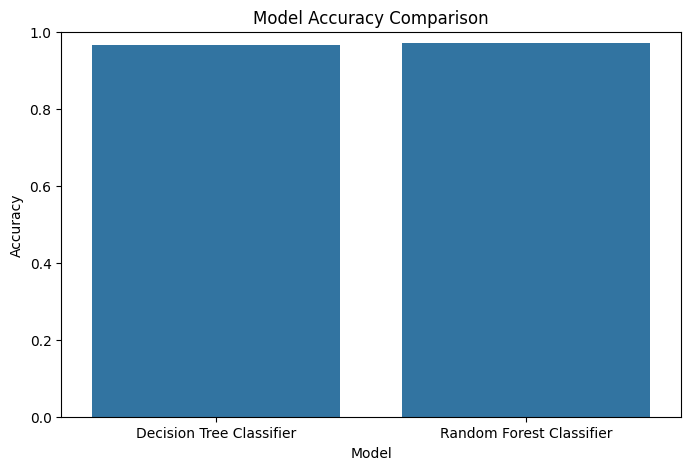

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")

plt.show()